# Traffic Analysis and Prediction
## TrafficRush — Predicting High Traffic Conditions Using Machine Learning
**CSE3141 · Manipal University Jaipur**

Can time, weekdays, holidays and weather help classify a historical highway hour as **High** or **Normal Traffic**? Binary Logistic Regression predicts whether hourly volume reaches the training-period 70th percentile. A high count does not necessarily mean a jam, crash risk or live traffic.

The supplied airline notebook was reinspected: 20 cells, including 11 code cells of 4–32 lines. This notebook follows its style: readable analysis, charts, preprocessing, training and metrics are written in the cells. Only reusable download and JSON-export work lives in `python_functions/`. The actual CSE3141 handout was reviewed; this project covers preparation, EDA, feature selection, Logistic Regression and chronological validation.

In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() if (Path.cwd() / "python_functions").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from python_functions.data import load_data
from python_functions.reporting import evaluate, export_results
sns.set_theme(style="whitegrid", palette=["#0d9488", "#f59e0b", "#334155"])
plt.rcParams["figure.figsize"] = (11, 4)
thread_limit = threadpool_limits(limits=1)

### 1. Load and inspect the real data
[UCI Metro Interstate Traffic Volume, dataset 492](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume) records hourly westbound I-94 counts at Minnesota ATR station 301. Temperature is Kelvin, precipitation is mm/hour and cloud cover is percent. Dates are source local CST wall-clock labels; no UTC/DST conversion is guessed. The helper downloads the official ZIP once, validates its contents, caches it and loads its CSV. The loader preserves the literal holiday label `None`; it must not be parsed as a missing value.

In [2]:
raw = load_data()
print("Source observations and columns:", raw.shape)
print("Columns:", raw.columns.tolist())
print("Exact duplicate records:", raw.duplicated().sum())
display(raw.head())
display(raw.dtypes.to_frame("data type"))
display(raw.isna().sum().to_frame("missing values"))
raw.info()

Source observations and columns: (48204, 9)
Columns: ['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']
Exact duplicate records: 17


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


,data type
holiday,object
temp,float64
rain_1h,float64
snow_1h,float64
clouds_all,int64
weather_main,object
weather_description,object
date_time,object
traffic_volume,int64


,missing values
holiday,0
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              48204 non-null  object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


### 2. Investigate duplicates, invalid measurements and outliers
Repeated timestamps can contain multiple weather reports for the same hourly count. Quarantine hours whose counts disagree; otherwise retain the first source weather report without selecting by target value. This avoids overweighting repeated hours. The source's holiday marker is propagated within its calendar date because holiday is known calendar information, not a future traffic outcome.

Zero Kelvin is physically invalid and becomes missing. Negative precipitation and invalid cloud percentages are also marked missing. Training-fit imputation will handle these values. IQR flags do not automatically delete unusual weather.

In [3]:
df = raw.drop_duplicates().copy()
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
print("Extra records sharing an hour:", df.date_time.duplicated().sum())
assert raw.holiday.notna().all() and raw.holiday.eq("None").any()
hourly_counts = df.groupby("date_time").traffic_volume.nunique()
conflicting_hours = hourly_counts[hourly_counts > 1].index
print("Hours with conflicting volume:", len(conflicting_hours))
df = df[~df.date_time.isin(conflicting_hours)]
df = df.dropna(subset=["date_time", "traffic_volume"])
# Calendar-day holiday information is independent of observed traffic counts.
df["is_holiday"] = (
    df.holiday.ne("None").groupby(df.date_time.dt.date).transform("max").astype(int)
)
df = df.drop_duplicates("date_time", keep="first")
df = df.sort_values("date_time").reset_index(drop=True)
numeric_source = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
df[numeric_source] = df[numeric_source].apply(pd.to_numeric, errors="coerce")
df = df[df.traffic_volume.ge(0)].copy()
assert df.date_time.is_unique

Extra records sharing an hour: 7612
Hours with conflicting volume: 0


In [4]:
print("Nonpositive Kelvin readings:", df.temp.le(0).sum())
df.loc[df.temp.le(0), "temp"] = np.nan
for column in ["rain_1h", "snow_1h"]:
    df.loc[df[column].lt(0), column] = np.nan
df.loc[~df.clouds_all.between(0, 100), "clouds_all"] = np.nan
df["temp_c"] = df.temp - 273.15
display(df[["temp_c", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]].describe())

columns = ["temp_c", "rain_1h", "snow_1h", "traffic_volume"]
q1, q3 = df[columns].quantile(.25), df[columns].quantile(.75)
flags = ((df[columns] < q1 - 1.5 * (q3 - q1)) |
         (df[columns] > q3 + 1.5 * (q3 - q1))).sum()
display(flags.to_frame("IQR flags retained"))
print("Largest rainfall measurements:", df.rain_1h.nlargest(3).tolist())
print("Unique usable hours:", len(df))
print("Coverage:", df.date_time.min(), "to", df.date_time.max())
display(Markdown("**Decision:** retain nonnegative weather extremes, report their possible leverage, "
                 "and learn imputation values from training only."))

Nonpositive Kelvin readings: 10


,temp_c,rain_1h,snow_1h,clouds_all,traffic_volume
count,40565.000000,40575.000000,40575.000000,40575.000000,40575.000000
mean,8.236113,0.318632,0.000117,44.199162,3290.650474
std,13.093185,48.812640,0.005676,38.683447,1984.772909
min,-29.760000,0.000000,0.000000,0.000000,0.000000
25%,-1.300000,0.000000,0.000000,1.000000,1248.500000
50%,9.720000,0.000000,0.000000,40.000000,3427.000000
75%,19.130000,0.000000,0.000000,90.000000,4952.000000
max,36.920000,9831.300000,0.510000,100.000000,7280.000000


,IQR flags retained
temp_c,0
rain_1h,2054
snow_1h,31
traffic_volume,0


Largest rainfall measurements: [9831.3, 55.63, 44.45]
Unique usable hours: 40575
Coverage: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


**Decision:** retain nonnegative weather extremes, report their possible leverage, and learn imputation values from training only.

### 3. Calendar features, chronological partitions and target
Hour, weekday and month will be categorical, allowing nonmonotonic rush-hour patterns. Weekend is useful for EDA but redundant with weekday, so it is excluded from both models. Keep unique hours in chronological 70%/15%/15% partitions. Calculate the volume cutoff using training alone, then apply the same rule everywhere. Traffic volume, raw timestamp and weather_description never enter the predictor matrix.

In [5]:
df["hour"] = df.date_time.dt.hour
df["day_of_week"] = df.date_time.dt.dayofweek
df["month"] = df.date_time.dt.month
df["is_weekend"] = df.day_of_week.ge(5).astype(int)
n = len(df)
train = df.iloc[:int(.70 * n)].copy()
valid = df.iloc[int(.70 * n):int(.85 * n)].copy()
test = df.iloc[int(.85 * n):].copy()
parts = {"train": train, "validation": valid, "test": test}
volume_threshold = float(train.traffic_volume.quantile(.70))
for block in [train, valid, test, df]:
    block["high_traffic"] = block.traffic_volume.ge(volume_threshold).astype(int)
assert train.date_time.max() < valid.date_time.min() < test.date_time.min()
assert not set(train.date_time) & set(test.date_time)
assert not set(train.date_time) & set(valid.date_time)
summary = []
for name, block in parts.items():
    assert block.high_traffic.nunique() == 2
    summary.append({"partition": name, "hours": len(block),
                    "start": block.date_time.min(), "end": block.date_time.max(),
                    "high_fraction": block.high_traffic.mean()})
display(pd.DataFrame(summary))
print("Training-only High Traffic cutoff:", volume_threshold, "vehicles/hour")
print("Holiday-hour distribution:", df.is_holiday.value_counts().to_dict())
assert set(df.is_holiday.unique()) == {0, 1}

,partition,hours,start,end,high_fraction
0,train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00,0.300190
1,validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00,0.316957
2,test,6087,2018-01-19 15:00:00,2018-09-30 23:00:00,0.315426


Training-only High Traffic cutoff: 4722.0 vehicles/hour
Holiday-hour distribution: {0: 39372, 1: 1203}


### 4. Exploratory analysis using training hours
Purpose → inspect count distributions, calendar rhythms and weather associations → decide on manageable features. Use training behavior for research decisions; the final test remains held out. Charts are descriptive group summaries, not causal evidence.

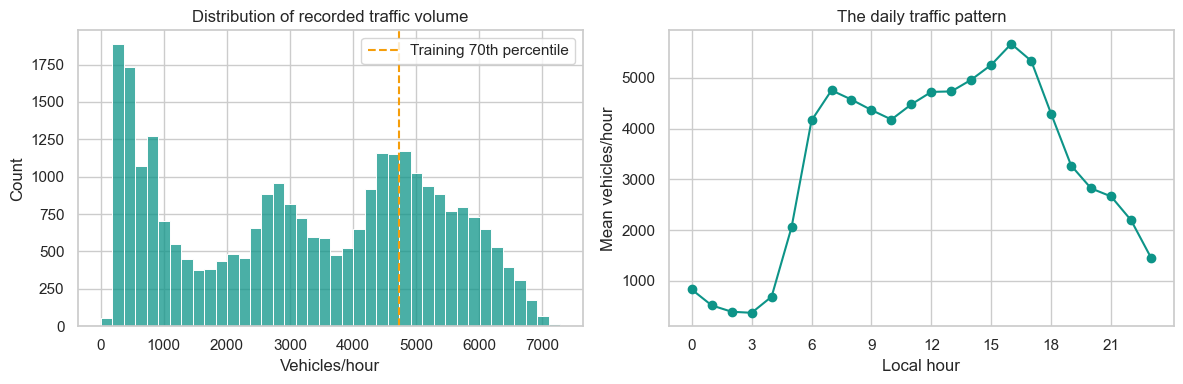

**Observed:** the largest training mean occurs at 16:00. Encode hour categorically rather than assume volume increases linearly all day.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train.traffic_volume, bins=40, ax=axes[0])
axes[0].axvline(volume_threshold, color="#f59e0b", ls="--", label="Training 70th percentile")
axes[0].set(xlabel="Vehicles/hour", title="Distribution of recorded traffic volume")
axes[0].legend()
hourly_mean = train.groupby("hour").traffic_volume.mean()
hourly_mean.plot(marker="o", ax=axes[1])
axes[1].set(xlabel="Local hour", ylabel="Mean vehicles/hour",
            title="The daily traffic pattern", xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()
display(Markdown(f"**Observed:** the largest training mean occurs at {hourly_mean.idxmax():02d}:00. "
                 "Encode hour categorically rather than assume volume increases linearly all day."))

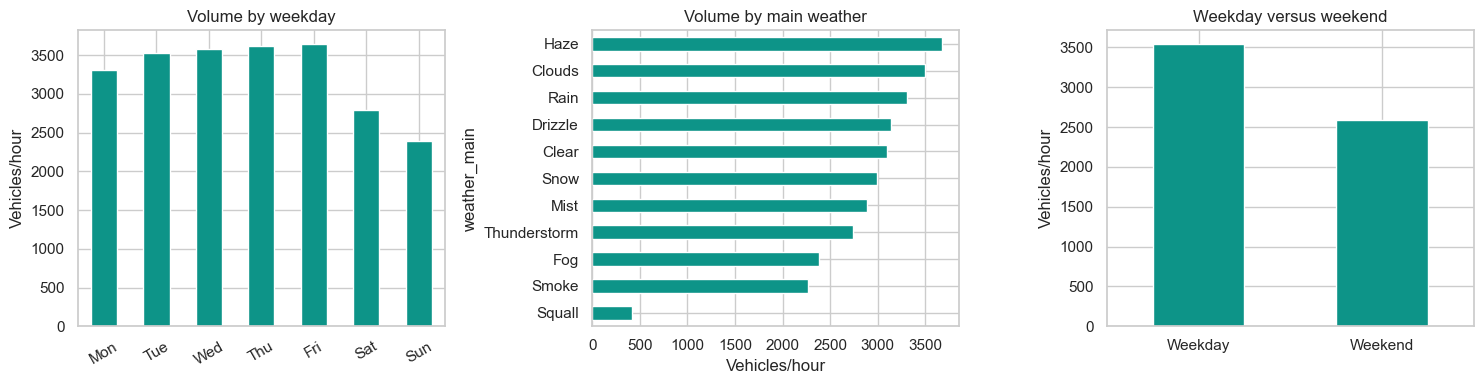

**Interpretation:** group means differ, but groups overlap in time and size. Compare weather with a controlled feature ablation rather than infer causality.

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
daily_mean = train.groupby("day_of_week").traffic_volume.mean()
daily_mean.plot.bar(ax=axes[0], rot=30)
axes[0].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].set(title="Volume by weekday", ylabel="Vehicles/hour", xlabel="")
weather_mean = train.groupby("weather_main").traffic_volume.mean().sort_values()
weather_mean.plot.barh(ax=axes[1])
axes[1].set(title="Volume by main weather", xlabel="Vehicles/hour")
weekend_mean = train.groupby("is_weekend").traffic_volume.mean()
weekend_mean.index = ["Weekday", "Weekend"]
weekend_mean.plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Weekday versus weekend", ylabel="Vehicles/hour", xlabel="")
plt.tight_layout()
plt.show()
display(Markdown("**Interpretation:** group means differ, but groups overlap in time and size. "
                 "Compare weather with a controlled feature ablation rather than infer causality."))

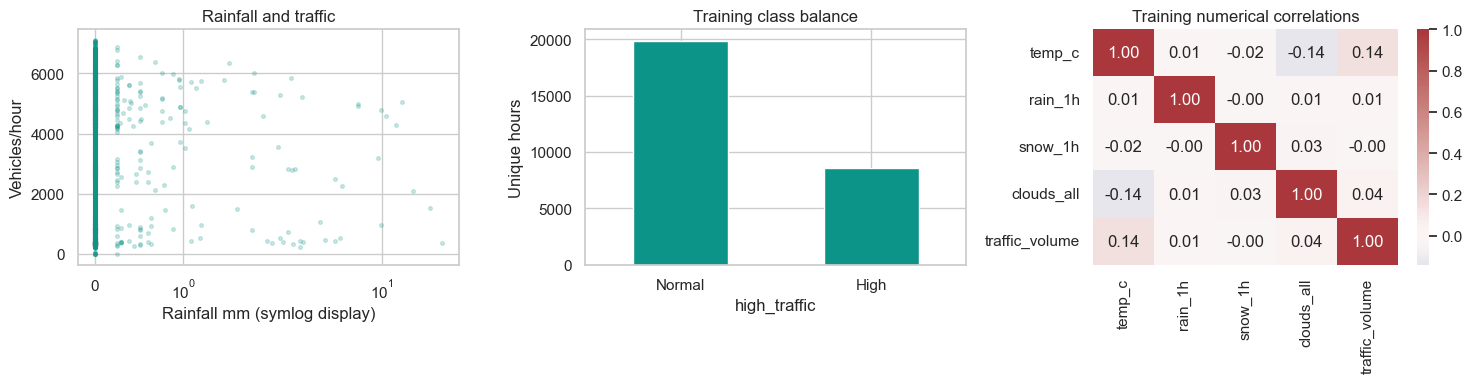

**Decision:** weather is skewed and its simple correlations are limited. Retain the compact weather group for validation, alongside stronger calendar features.

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rain_plot = train[train.rain_1h.notna()]
rain_plot = rain_plot.sample(min(3000, len(rain_plot)), random_state=42)
axes[0].scatter(rain_plot.rain_1h, rain_plot.traffic_volume, s=7, alpha=.2)
axes[0].set(xscale="symlog", xlabel="Rainfall mm (symlog display)",
            ylabel="Vehicles/hour", title="Rainfall and traffic")
train.high_traffic.value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set_xticklabels(["Normal", "High"])
axes[1].set(title="Training class balance", ylabel="Unique hours")
correlation = train[["temp_c", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]].corr()
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[2])
axes[2].set_title("Training numerical correlations")
plt.tight_layout()
plt.show()
display(Markdown("**Decision:** weather is skewed and its simple correlations are limited. "
                 "Retain the compact weather group for validation, alongside stronger calendar features."))

### 5. Preprocessing and the primary Logistic Regression pipeline
As in the airline reference, construct the actual preprocessing and classifier below. Median imputation/scaling handles numeric inputs; most-frequent imputation and one-hot encoding handles categoricals. Unknown categories are ignored without refitting. Time + weather is the predeclared primary model; time only will be its research comparison. Numeric volume, raw date_time and detailed weather description are excluded.

In [9]:
time_numeric = ["is_holiday"]
time_categorical = ["hour", "day_of_week", "month"]
all_numeric = time_numeric + ["temp_c", "rain_1h", "snow_1h", "clouds_all"]
all_categorical = time_categorical + ["weather_main"]
time_features = time_numeric + time_categorical
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, all_numeric),
    ("cat", categorical_pipeline, all_categorical)
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, solver="lbfgs", random_state=42))
])
X_train, y_train = train[all_numeric + all_categorical], train.high_traffic
X_valid, y_valid = valid[all_numeric + all_categorical], valid.high_traffic
X_test, y_test = test[all_numeric + all_categorical], test.high_traffic
print("Primary predictors:", X_train.columns.tolist())

Primary predictors: ['is_holiday', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'hour', 'day_of_week', 'month', 'weather_main']


### 6. Train and tune with chronological validation
Logistic Regression estimates p(High) using a sigmoid of the weighted encoded inputs. Classify High when p≥0.5. Smaller C gives stronger L2 shrinkage. Search C ∈ {0.1, 1, 10} using a predefined chronological validation fold and F1; this is not repeated random cross-validation. Disable automatic refitting on the combined pool so all learned preprocessing and coefficients stay training-fit. Test data never chooses C.

In [10]:
pool = pd.concat([train, valid], ignore_index=True)
fold = PredefinedSplit(np.r_[np.full(len(train), -1), np.zeros(len(valid), dtype=int)])
search = GridSearchCV(
    model, {"classifier__C": [.1, 1., 10.]}, cv=fold, scoring="f1",
    refit=False, return_train_score=True, error_score="raise", n_jobs=1
)
search.fit(pool[all_numeric + all_categorical], pool.high_traffic)
model.set_params(**search.best_params_)
model.fit(X_train, y_train)
assert model.named_steps["classifier"].n_iter_.max() < 2000

weather_tuning = pd.DataFrame({
    "model": "time_weather",
    "C": [p["classifier__C"] for p in search.cv_results_["params"]],
    "training_f1": search.cv_results_["mean_train_score"],
    "validation_f1": search.cv_results_["mean_test_score"]
})
display(weather_tuning)
print("Chosen C:", search.best_params_)
print("Validation F1:", evaluate(y_valid, model.predict(X_valid),
                                 model.predict_proba(X_valid)[:, 1])["f1"])

,model,C,training_f1,validation_f1
0,time_weather,0.1,0.874832,0.884636
1,time_weather,1.0,0.875981,0.883302
2,time_weather,10.0,0.875791,0.882135


Chosen C: {'classifier__C': 0.1}
Validation F1: 0.8846358320042531


### 7. Held-out test evaluation
Freeze the fitted pipeline, then generate actual test predictions. Accuracy, precision, recall, F1 and ROC-AUC measure different aspects. The majority baseline supplies context. Ranking AUC does not establish calibrated probabilities. Validation is a model-selection estimate, while test is the final evaluation.

In [11]:
predicted = model.predict(X_test)
probability = model.predict_proba(X_test)[:, 1]
test_scores = {
    "accuracy": float(accuracy_score(y_test, predicted)),
    "precision": float(precision_score(y_test, predicted, zero_division=0)),
    "recall": float(recall_score(y_test, predicted, zero_division=0)),
    "f1": float(f1_score(y_test, predicted, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, probability))
}
display(pd.Series(test_scores, name="primary test metrics"))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train[["hour"]], y_train)
baseline = evaluate(y_test, dummy.predict(test[["hour"]]),
                    dummy.predict_proba(test[["hour"]])[:, 1])
display(pd.Series(baseline, name="majority baseline"))
report = classification_report(
    y_test, predicted, target_names=["Normal Traffic", "High Traffic"],
    output_dict=True, zero_division=0
)
display(pd.DataFrame(report).T)
print(f"Test accuracy: {test_scores['accuracy']:.2%}")
print(f"Test F1: {test_scores['f1']:.4f}")
print(f"Test ROC-AUC: {test_scores['roc_auc']:.4f}")

accuracy     0.932150
precision    0.896788
recall       0.886979
f1           0.891857
roc_auc      0.978520
Name: primary test metrics, dtype: float64

accuracy     0.684574
precision    0.000000
recall       0.000000
f1           0.000000
roc_auc      0.500000
Name: majority baseline, dtype: float64

,precision,recall,f1-score,support
Normal Traffic,0.948185,0.952964,0.950569,4167.00000
High Traffic,0.896788,0.886979,0.891857,1920.00000
accuracy,0.932150,0.932150,0.932150,0.93215
macro avg,0.922487,0.919971,0.921213,6087.00000
weighted avg,0.931973,0.932150,0.932049,6087.00000


Test accuracy: 93.22%
Test F1: 0.8919
Test ROC-AUC: 0.9785


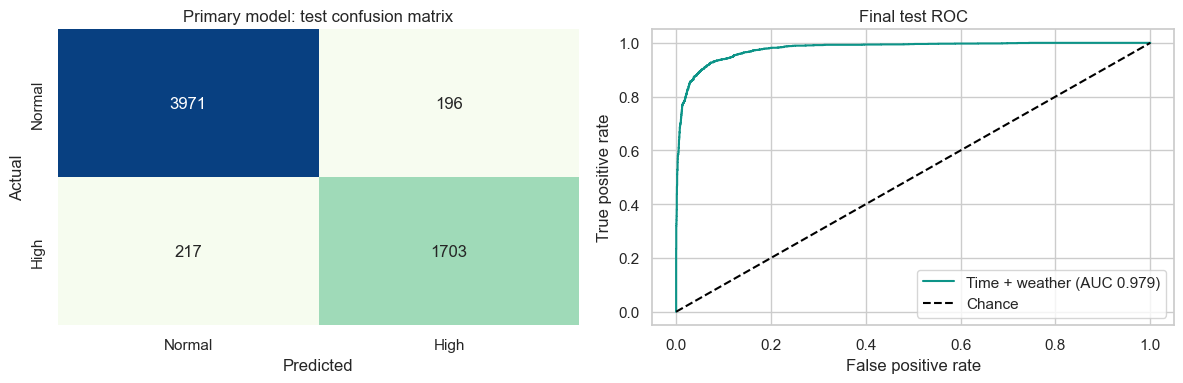

**Observed:** 196 false positives and 217 false negatives. The confusion matrix makes errors visible; no test result triggers retuning.

In [12]:
cm = confusion_matrix(y_test, predicted, labels=[0, 1])
fpr, tpr, _ = roc_curve(y_test, probability)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="GnBu", cbar=False,
            xticklabels=["Normal", "High"], yticklabels=["Normal", "High"], ax=axes[0])
axes[0].set(xlabel="Predicted", ylabel="Actual", title="Primary model: test confusion matrix")
axes[1].plot(fpr, tpr, label=f"Time + weather (AUC {test_scores['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="Final test ROC")
axes[1].legend()
plt.tight_layout()
plt.show()
display(Markdown(f"**Observed:** {cm[0,1]} false positives and {cm[1,0]} false negatives. "
                 "The confusion matrix makes errors visible; no test result triggers retuning."))

### 8. Original experiment: does weather improve prediction?
Train a second Logistic Regression using calendar information only, with identical partitions, C grid and validation criterion. Clone preprocessing components so fitting this model cannot mutate the primary pipeline. Compare actual validation and test F1/AUC. Preserve the primary time + weather model whether the difference is positive or negative.

In [13]:
time_preprocessor = ColumnTransformer([
    ("num", clone(numeric_pipeline), time_numeric),
    ("cat", clone(categorical_pipeline), time_categorical)
])
time_model = clone(model).set_params(preprocessor=time_preprocessor)
time_search = GridSearchCV(
    time_model, {"classifier__C": [.1, 1., 10.]}, cv=fold, scoring="f1",
    refit=False, return_train_score=True, error_score="raise", n_jobs=1
)
time_search.fit(pool[time_features], pool.high_traffic)
time_model.set_params(**time_search.best_params_).fit(train[time_features], y_train)
time_tuning = pd.DataFrame({
    "model": "time_only",
    "C": [p["classifier__C"] for p in time_search.cv_results_["params"]],
    "training_f1": time_search.cv_results_["mean_train_score"],
    "validation_f1": time_search.cv_results_["mean_test_score"]
})
tuning = pd.concat([time_tuning, weather_tuning], ignore_index=True)
models = {"time_only": time_model, "time_weather": model}
rows = []
for partition, block in parts.items():
    for name, fitted in models.items():
        features = fitted.feature_names_in_
        scores = evaluate(block.high_traffic, fitted.predict(block[features]),
                          fitted.predict_proba(block[features])[:, 1])
        rows.append(dict(partition=partition, model=name, **scores))
evaluation = pd.DataFrame(rows)
comparison = evaluation[evaluation.partition.isin(["validation", "test"])]
display(comparison[["partition", "model", "f1", "roc_auc"]])
test_comparison = evaluation[evaluation.partition.eq("test")].set_index("model")
weather_gain = test_comparison.loc["time_weather", ["f1", "roc_auc"]] - test_comparison.loc["time_only", ["f1", "roc_auc"]]
display(weather_gain.to_frame("weather minus time-only"))

,partition,model,f1,roc_auc
2,validation,time_only,0.885517,0.973870
3,validation,time_weather,0.884636,0.975296
4,test,time_only,0.890465,0.977560
5,test,time_weather,0.891857,0.978520


,weather minus time-only
f1,0.001392
roc_auc,0.00096


### 9. Interpret coefficients and export the real trained model
Inspect the actual fitted coefficients below. Numeric coefficients apply per training standard deviation; encoded category coefficients are regularized associations, not causal effects. Save the entire pipeline with Joblib. The reporting helper only packages already-computed results and descriptive JSON for FastAPI; it does not select features or train a separate model.

In [14]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": model.named_steps["classifier"].coef_[0]
})
coefficients["magnitude"] = coefficients.coefficient.abs()
coefficients = coefficients.sort_values("magnitude", ascending=False)
display(coefficients.head(15))

artifacts = ROOT / "backend/artifacts"
artifacts.mkdir(parents=True, exist_ok=True)
joblib.dump(model, artifacts / "traffic_model.joblib")
results = dict(test_scores=test_scores, baseline=baseline, cm=cm, report=report,
               comparison=comparison, evaluation=evaluation, fpr=fpr, tpr=tpr,
               probability=probability)
export_results(raw, df, parts, volume_threshold, model, tuning, results, coefficients)
reloaded = joblib.load(artifacts / "traffic_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], probability)
print("Model reload verified; backend receives this same trained pipeline.")

,feature,coefficient,magnitude
21,cat__hour_16,3.410465,3.410465
20,cat__hour_15,3.355437,3.355437
35,cat__day_of_week_6,-3.341959,3.341959
19,cat__hour_14,3.039954,3.039954
22,cat__hour_17,3.020958,3.020958
12,cat__hour_7,2.864594,2.864594
11,cat__hour_6,2.804354,2.804354
13,cat__hour_8,2.739091,2.739091
24,cat__hour_19,-2.641243,2.641243
25,cat__hour_20,-2.632649,2.632649


Exported fitted pipeline, actual metrics, summaries and parity cases.
Model reload verified; backend receives this same trained pipeline.


### 10. Conclusions, background and limitations
Predictive analytics distinguishes descriptive patterns from unseen-hour classification. UCI supplies regression counts; this project creates a training-defined binary label. The held-out weather comparison asks whether detailed weather adds information beyond the calendar. A small measured gain is not proof of causality or statistical significance.

The source covers one station in 2012–2018, not current road conditions or a network of highways. Repeated weather reports were reduced to one record per hour, losing detail. Missing hours, nonnegative weather extremes and invalid-temperature sentinels are limitations. Supplied same-hour weather is assumed available, not independently forecast. Adjacent hours are dependent; validation is reused for C selection; probabilities have no independent calibration study.

Future work: additional stations/years, rolling-origin evaluation and a separate calibration block. No traffic-jam, collision or live-report claim is made.

References: Hogue, J. (2019), [Metro Interstate Traffic Volume](https://doi.org/10.24432/C5X60B), UCI (CC BY 4.0); [scikit-learn Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html); the supplied CSE3141 handout and airline ZIP as course/style references.

In [15]:
display(Markdown(
    f"**Completed:** {len(raw):,} source records → {len(df):,} unique hours. "
    f"High Traffic is ≥{volume_threshold:,.0f} vehicles/hour. "
    f"Test accuracy **{test_scores['accuracy']:.2%}**, F1 **{test_scores['f1']:.3f}**, "
    f"ROC-AUC **{test_scores['roc_auc']:.3f}**. "
    f"Weather changes F1 by **{weather_gain.f1:+.3f}** and AUC by **{weather_gain.roc_auc:+.3f}**. "
    "These are historical count-category estimates, not congestion or crash predictions."
))

**Completed:** 48,204 source records → 40,575 unique hours. High Traffic is ≥4,722 vehicles/hour. Test accuracy **93.22%**, F1 **0.892**, ROC-AUC **0.979**. Weather changes F1 by **+0.001** and AUC by **+0.001**. These are historical count-category estimates, not congestion or crash predictions.